In [1]:
# Load frozen development data and register feature-family experiments.
# No fitting or final-test access.

from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import sys

import numpy as np
import pandas as pd

roots = [
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/processed/acoustic_features_recording.csv").is_file()
]
assert len(roots) == 1
PROJECT_ROOT = roots[0]

artifact_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1"
    / "assignment_artifacts_20261030T020845905141Z"
)
artifacts = json.loads(
    (artifact_dir / "artifact_manifest.json").read_text(encoding="utf-8")
)
feature_names = artifacts["feature_allowlist"]
CLASSES = ["CA", "AZ", "TX"]

dt_checkpoint = (
    PROJECT_ROOT / "data/processed/supervised/v1/decision_trees"
    / "development_search_20261030T031713485157Z"
    / "selected_checkpoint_20261030T032419146939Z/selected_tree.json"
)
dt_selection = json.loads(dt_checkpoint.read_text(encoding="utf-8"))
reference_tree_spec = dt_selection["configuration"]

fold_manifest = pd.read_csv(
    PROJECT_ROOT / artifacts["development_folds"],
    dtype={"recording_id": "string"},
)
training_export = pd.read_csv(
    artifact_dir / "development_train.csv",
    dtype={"recording_id": "string"},
)

assert training_export["recording_id"].is_unique
assert set(training_export["recording_id"]) == set(fold_manifest["recording_id"])

ordered = training_export.set_index("recording_id").loc[
    fold_manifest["recording_id"]
]
for column in ["model_state", "location_group"]:
    assert np.array_equal(
        ordered[column].to_numpy(), fold_manifest[column].to_numpy()
    )

X = ordered[feature_names].reset_index(drop=True)
y = fold_manifest["model_state"].reset_index(drop=True)
assert X.shape == (184, 50)
assert np.isfinite(X.to_numpy()).all()

def assign_family(feature):
    if feature.startswith("mfcc_"):
        return "MFCC"
    if feature.startswith((
        "aci_", "adi_", "bioacoustic_index_",
        "ndsi_", "anthropophony_", "biophony_",
    )):
        return "Ecoacoustic indices and band summaries"
    if feature.startswith("spectral_"):
        return "Spectral shape and entropy"
    if feature.startswith(("temporal_entropy_", "rms_", "zcr_")):
        return "Temporal and amplitude"
    raise ValueError(f"Unassigned feature: {feature}")

feature_dictionary = pd.DataFrame({
    "feature": feature_names,
    "analysis_family": [assign_family(f) for f in feature_names],
})

original_manifest = pd.read_csv(
    PROJECT_ROOT / "data/manifests/feature_manifest.csv"
)
assert original_manifest["feature_name"].is_unique

feature_dictionary = feature_dictionary.merge(
    original_manifest,
    left_on="feature",
    right_on="feature_name",
    how="left",
    validate="one_to_one",
)
assert len(feature_dictionary) == 50
assert feature_dictionary["feature_name"].notna().all()

feature_sets = {"All features": list(feature_names)}

for family, rows in feature_dictionary.groupby("analysis_family"):
    feature_sets[f"{family} only"] = rows["feature"].tolist()

feature_sets["Without MFCC"] = [
    feature for feature in feature_names if not feature.startswith("mfcc_")
]

print("FEATURE FAMILIES")
print(
    feature_dictionary.groupby("analysis_family").size()
    .rename("features").to_string()
)

print("\nREGISTERED COMPARISONS")
for name, columns in feature_sets.items():
    print(f"{name}: {len(columns)} features")

print("\nREFERENCE TREE — FIXED PARAMETERS")
print(json.dumps(reference_tree_spec, indent=2))

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
family_run_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1"
    / f"feature_families_{stamp}"
)
family_run_dir.mkdir(parents=True, exist_ok=False)

feature_dictionary.to_csv(
    family_run_dir / "feature_dictionary.csv", index=False
)
(family_run_dir / "experiment_protocol.json").write_text(
    json.dumps({
        "purpose": "Feature-family contribution under a fixed tree configuration",
        "timing": "Extension after initial NB/tree development comparisons",
        "reference_tree": reference_tree_spec,
        "feature_sets": feature_sets,
        "fold_manifest": artifacts["development_folds"],
        "fold_manifest_sha256": hashlib.sha256(
            (PROJECT_ROOT / artifacts["development_folds"]).read_bytes()
        ).hexdigest(),
        "retune_per_feature_set": False,
        "final_test_evaluated": False,
        "interpretation_limits": [
            "Results are conditional on the fixed tree configuration.",
            "Families are analysis categories, not independent physical causes.",
            "Zero-crossing rate also relates to spectral content.",
            "Feature counts differ; this is not an equal-dimensional comparison.",
            "Removing a family can leave correlated information elsewhere.",
        ],
    }, indent=2),
    encoding="utf-8",
)

print("\nSaved:", family_run_dir)


FEATURE FAMILIES
analysis_family
Ecoacoustic indices and band summaries     7
MFCC                                      26
Spectral shape and entropy                12
Temporal and amplitude                     5

REGISTERED COMPARISONS
All features: 50 features
Ecoacoustic indices and band summaries only: 7 features
MFCC only: 26 features
Spectral shape and entropy only: 12 features
Temporal and amplitude only: 5 features
Without MFCC: 24 features

REFERENCE TREE — FIXED PARAMETERS
{
  "name": "Gini_depth3",
  "family": "fixed_gini",
  "criterion": "gini",
  "max_depth": 3,
  "min_samples_leaf": 5,
  "ccp_alpha": 0.0
}

Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\feature_families_20261030T222433272446Z


Completed: All features
Completed: Ecoacoustic indices and band summaries only
Completed: MFCC only
Completed: Spectral shape and entropy only
Completed: Temporal and amplitude only
Completed: Without MFCC

FEATURE-FAMILY COMPARISON
                                 experiment  features  mean_macro_f1  sd_macro_f1  mean_accuracy  mean_balanced_accuracy  mean_delta_vs_all
                Temporal and amplitude only         5         0.4628       0.0985         0.5098                  0.5033             0.0111
                               All features        50         0.4517       0.0799         0.4858                  0.4601             0.0000
            Spectral shape and entropy only        12         0.4236       0.0466         0.4692                  0.4530            -0.0281
                               Without MFCC        24         0.4121       0.1000         0.4298                  0.4201            -0.0395
                                  MFCC only        26         0.378

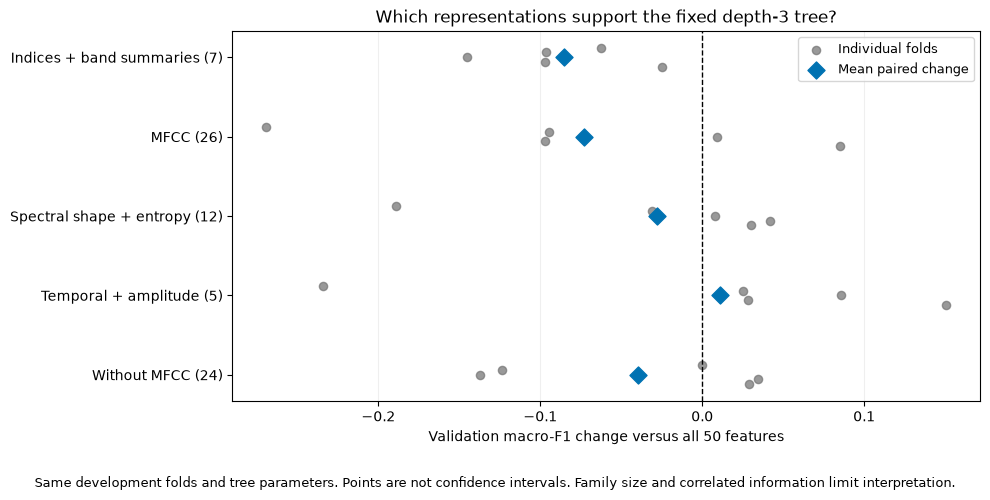


Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\feature_families_20261030T222433272446Z
All-feature reference reproduced..


In [2]:

# Fixed-tree feature-family comparisons; no tuning or final-test access.

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score
)
import matplotlib.pyplot as plt

tree_parameters = {
    key: reference_tree_spec[key]
    for key in ["criterion", "max_depth", "min_samples_leaf", "ccp_alpha"]
}

family_fold_rows = []
family_prediction_rows = []

for experiment, columns in feature_sets.items():
    for fold in range(5):
        validation_mask = fold_manifest["validation_fold"].eq(fold)
        train_idx = np.flatnonzero(~validation_mask.to_numpy())
        validation_idx = np.flatnonzero(validation_mask.to_numpy())

        assert set(
            fold_manifest.iloc[train_idx]["location_group"]
        ).isdisjoint(
            fold_manifest.iloc[validation_idx]["location_group"]
        )

        pipeline = Pipeline([
            ("impute", SimpleImputer(
                strategy="median", keep_empty_features=True
            )),
            ("classifier", DecisionTreeClassifier(
                **tree_parameters, random_state=42
            )),
        ])
        pipeline.fit(X.iloc[train_idx][columns], y.iloc[train_idx])
        predicted = pipeline.predict(X.iloc[validation_idx][columns])

        tree = pipeline.named_steps["classifier"]
        root_index = tree.tree_.feature[0]

        family_fold_rows.append({
            "experiment": experiment,
            "features": len(columns),
            "fold": fold,
            "validation_n": len(validation_idx),
            "macro_f1": f1_score(
                y.iloc[validation_idx], predicted,
                labels=CLASSES, average="macro", zero_division=0,
            ),
            "accuracy": accuracy_score(y.iloc[validation_idx], predicted),
            "balanced_accuracy": balanced_accuracy_score(
                y.iloc[validation_idx], predicted
            ),
            "leaves": tree.get_n_leaves(),
            "root_feature": columns[root_index] if root_index >= 0 else "NO_SPLIT",
        })

        for position, prediction in zip(validation_idx, predicted):
            record = fold_manifest.iloc[position]
            family_prediction_rows.append({
                "experiment": experiment,
                "recording_id": record["recording_id"],
                "location_group": record["location_group"],
                "validation_fold": fold,
                "actual": record["model_state"],
                "predicted": prediction,
            })

    print("Completed:", experiment)

family_folds = pd.DataFrame(family_fold_rows)
family_oof = pd.DataFrame(family_prediction_rows)

assert len(family_folds) == 30
assert family_oof.groupby("experiment").size().eq(184).all()
assert not family_oof.duplicated(["experiment", "recording_id"]).any()

# Reproduce the original all-feature tree scores.
original_tree_folds = pd.read_csv(
    dt_checkpoint.parent.parent / "fold_metrics.csv"
)
reference_scores = (
    original_tree_folds.loc[
        original_tree_folds["configuration"].eq(reference_tree_spec["name"])
    ].sort_values("fold")["macro_f1"].to_numpy()
)
reproduced_scores = (
    family_folds.loc[family_folds["experiment"].eq("All features")]
    .sort_values("fold")["macro_f1"].to_numpy()
)
assert np.allclose(reference_scores, reproduced_scores), (
    "All-feature reference did not reproduce; inspect before interpreting."
)

baseline = family_folds.loc[
    family_folds["experiment"].eq("All features"),
    ["fold", "macro_f1"],
].rename(columns={"macro_f1": "all_feature_macro_f1"})

family_folds = family_folds.merge(
    baseline, on="fold", validate="many_to_one"
)
family_folds["paired_delta"] = (
    family_folds["macro_f1"] - family_folds["all_feature_macro_f1"]
)

family_summary = (
    family_folds.groupby(["experiment", "features"], as_index=False)
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        sd_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_delta_vs_all=("paired_delta", "mean"),
    )
)

print("\nFEATURE-FAMILY COMPARISON")
print(
    family_summary.sort_values("mean_macro_f1", ascending=False)
    .round(4).to_string(index=False)
)

print("\nPAIRED MACRO-F1 CHANGES BY FOLD")
print(
    family_folds.pivot(
        index="experiment", columns="fold", values="paired_delta"
    ).round(3).to_string()
)

# Preserve the predefined comparison order rather than ranking visually.
plot_order = [name for name in feature_sets if name != "All features"]
short_names = {
    "Ecoacoustic indices and band summaries only": "Indices + band summaries (7)",
    "MFCC only": "MFCC (26)",
    "Spectral shape and entropy only": "Spectral shape + entropy (12)",
    "Temporal and amplitude only": "Temporal + amplitude (5)",
    "Without MFCC": "Without MFCC (24)",
}

fig, ax = plt.subplots(figsize=(10, 5))
for position, name in enumerate(plot_order):
    rows = family_folds.loc[
        family_folds["experiment"].eq(name)
    ].sort_values("fold")

    ax.scatter(
        rows["paired_delta"],
        position + np.linspace(-0.12, 0.12, len(rows)),
        color="#777777", alpha=0.75, s=35,
        label="Individual folds" if position == 0 else None,
    )
    ax.scatter(
        rows["paired_delta"].mean(), position,
        color="#0072B2", marker="D", s=75,
        label="Mean paired change" if position == 0 else None,
    )

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(
    range(len(plot_order)), [short_names[name] for name in plot_order]
)
ax.invert_yaxis()
ax.set_xlabel("Validation macro-F1 change versus all 50 features")
ax.set_title("Which representations support the fixed depth-3 tree?")
ax.grid(axis="x", alpha=0.2)
ax.legend(fontsize=9)

fig.text(
    0.5, 0.015,
    "Same development folds and tree parameters. Points are not confidence "
    "intervals. Family size and correlated information limit interpretation.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=[0, 0.07, 1, 1])
fig.savefig(
    family_run_dir / "feature_family_paired_changes.png",
    dpi=180, bbox_inches="tight",
)
fig.savefig(
    family_run_dir / "feature_family_paired_changes.svg",
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

family_folds.to_csv(family_run_dir / "fold_metrics.csv", index=False)
family_summary.to_csv(family_run_dir / "summary.csv", index=False)
family_oof.to_csv(family_run_dir / "oof_predictions.csv", index=False)

print("\nSaved:", family_run_dir)
print("All-feature reference reproduced..")

In [3]:
# Quality sensitivity with matched validation recordings
# Fixed all-feature tree; existing folds; final test untouched.

eligibility_path = (
    PROJECT_ROOT / "data/processed/supervised/audit"
    / "eligibility_20261030T011435890786Z/cohort_membership.csv"
)
eligibility = pd.read_csv(
    eligibility_path, dtype={"recording_id": "string"}
)
assert eligibility["recording_id"].is_unique

flag_text = eligibility["sensitivity_eligible"].astype("string").str.lower()
assert flag_text.isin(["true", "false"]).all()
eligibility["sensitivity_eligible"] = flag_text.eq("true")

eligible_lookup = eligibility.set_index("recording_id")["sensitivity_eligible"]
assert set(fold_manifest["recording_id"]).issubset(eligible_lookup.index)

eligible = (
    fold_manifest["recording_id"].map(eligible_lookup).to_numpy(dtype=bool)
)
assert eligible.sum() == 178

# Existing all-feature predictions: do not refit the reference.
reference_oof = family_oof.loc[
    family_oof["experiment"].eq("All features")
].set_index("recording_id")
assert reference_oof.index.is_unique

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
quality_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1"
    / f"quality_sensitivity_{stamp}"
)
quality_dir.mkdir(parents=True, exist_ok=False)

(quality_dir / "protocol.json").write_text(
    json.dumps({
        "reference_tree": reference_tree_spec,
        "feature_allowlist": feature_names,
        "fold_manifest": artifacts["development_folds"],
        "eligibility_file": str(eligibility_path.relative_to(PROJECT_ROOT)),
        "comparison": (
            "Original versus quality-restricted training, evaluated on "
            "identical eligible validation recordings within each fold."
        ),
        "matched_validation_total": int(eligible.sum()),
        "retuning": False,
        "primary_cohort_changed": False,
        "final_test_evaluated": False,
    }, indent=2),
    encoding="utf-8",
)

quality_scores = []
quality_predictions = []
quality_support = []

for fold in range(5):
    fold_values = fold_manifest["validation_fold"].to_numpy()
    original_train = np.flatnonzero(fold_values != fold)
    restricted_train = np.flatnonzero((fold_values != fold) & eligible)
    matched_validation = np.flatnonzero((fold_values == fold) & eligible)

    assert set(y.iloc[restricted_train]) == set(CLASSES)
    assert set(y.iloc[matched_validation]) == set(CLASSES)
    assert set(
        fold_manifest.iloc[restricted_train]["location_group"]
    ).isdisjoint(
        fold_manifest.iloc[matched_validation]["location_group"]
    )

    pipeline = Pipeline([
        ("impute", SimpleImputer(
            strategy="median", keep_empty_features=True
        )),
        ("classifier", DecisionTreeClassifier(
            **tree_parameters, random_state=42
        )),
    ])
    pipeline.fit(X.iloc[restricted_train], y.iloc[restricted_train])

    ids = fold_manifest.iloc[matched_validation]["recording_id"].tolist()
    actual = y.iloc[matched_validation].to_numpy()
    reference_rows = reference_oof.loc[ids]

    assert np.array_equal(reference_rows["actual"].to_numpy(), actual)
    assert reference_rows["validation_fold"].eq(fold).all()

    predictions = {
        "Original training": reference_rows["predicted"].to_numpy(),
        "Quality-restricted training": pipeline.predict(
            X.iloc[matched_validation]
        ),
    }

    quality_support.append({
        "fold": fold,
        "original_training_n": len(original_train),
        "restricted_training_n": len(restricted_train),
        "matched_validation_n": len(matched_validation),
    })

    for condition, predicted in predictions.items():
        quality_scores.append({
            "condition": condition,
            "fold": fold,
            "macro_f1": f1_score(
                actual, predicted, labels=CLASSES,
                average="macro", zero_division=0,
            ),
            "accuracy": accuracy_score(actual, predicted),
            "balanced_accuracy": balanced_accuracy_score(actual, predicted),
        })

        for rid, truth, prediction in zip(ids, actual, predicted):
            quality_predictions.append({
                "condition": condition,
                "recording_id": rid,
                "fold": fold,
                "actual": truth,
                "predicted": prediction,
            })

quality_scores = pd.DataFrame(quality_scores)
quality_predictions = pd.DataFrame(quality_predictions)
quality_support = pd.DataFrame(quality_support)

assert quality_predictions.groupby("condition").size().eq(178).all()
assert not quality_predictions.duplicated(
    ["condition", "recording_id"]
).any()

paired_quality = quality_scores.pivot(
    index="fold", columns="condition", values="macro_f1"
)
paired_quality["restricted_minus_original"] = (
    paired_quality["Quality-restricted training"]
    - paired_quality["Original training"]
)

print("MATCHED COMPARISON SUPPORT")
print(quality_support.to_string(index=False))

print("\nMEAN FOLD SCORES — SAME VALIDATION RECORDINGS")
print(
    quality_scores.groupby("condition")[
        ["macro_f1", "accuracy", "balanced_accuracy"]
    ].mean().round(4).to_string()
)

print("\nPAIRED MACRO-F1")
print(paired_quality.round(4).to_string())

quality_scores.to_csv(quality_dir / "fold_metrics.csv", index=False)
quality_predictions.to_csv(quality_dir / "oof_predictions.csv", index=False)
quality_support.to_csv(quality_dir / "support.csv", index=False)
paired_quality.to_csv(quality_dir / "paired_changes.csv")

print("\nSaved:", quality_dir)
print("Primary cohort and final-test partition unchanged.")

MATCHED COMPARISON SUPPORT
 fold  original_training_n  restricted_training_n  matched_validation_n
    0                  150                    144                    34
    1                  152                    148                    30
    2                  131                    127                    51
    3                  154                    150                    28
    4                  149                    143                    35

MEAN FOLD SCORES — SAME VALIDATION RECORDINGS
                             macro_f1  accuracy  balanced_accuracy
condition                                                         
Original training              0.4505    0.4881             0.4552
Quality-restricted training    0.4183    0.4252             0.4251

PAIRED MACRO-F1
condition  Original training  Quality-restricted training  restricted_minus_original
fold                                                                                
0                     0.5517           

In [4]:
#  Regularized logistic classification
# Two representations × three regularization settings.
# Fixed development folds; no final-test access.

import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import log_loss

module_path = PROJECT_ROOT / "research/src/supervised/representations.py"
assert hashlib.sha256(module_path.read_bytes()).hexdigest() == (
    artifacts["representation_module_sha256"]
)

source_dir = str(PROJECT_ROOT / "research/src")
if source_dir not in sys.path:
    sys.path.insert(0, source_dir)
from supervised.representations import make_representations

PROB_CLASSES = np.array(["AZ", "CA", "TX"])
prob_columns = [f"p_{state}" for state in PROB_CLASSES]

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
logistic_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1"
    / f"logistic_comparison_{stamp}"
)
logistic_dir.mkdir(parents=True, exist_ok=False)

(logistic_dir / "protocol.json").write_text(
    json.dumps({
        "representations": ["continuous_standardized", "five_bin_onehot"],
        "C_values": [0.1, 1.0, 10.0],
        "solver": "lbfgs",
        "max_iter": 3000,
        "selection_metric": "Mean validation-fold macro-F1",
        "tie_rule": "Within 1e-12 of maximum: smaller C",
        "fold_manifest": artifacts["development_folds"],
        "timing": "Planned extension after initial NB/tree exploration",
        "final_test_evaluated": False,
    }, indent=2),
    encoding="utf-8",
)

logistic_fold_rows = []
logistic_prediction_rows = []

for representation_name in ["continuous_standardized", "five_bin_onehot"]:
    for C in [0.1, 1.0, 10.0]:
        for fold in range(5):
            validation_mask = fold_manifest["validation_fold"].eq(fold)
            tr = np.flatnonzero(~validation_mask.to_numpy())
            va = np.flatnonzero(validation_mask.to_numpy())

            assert set(
                fold_manifest.iloc[tr]["location_group"]
            ).isdisjoint(fold_manifest.iloc[va]["location_group"])

            if representation_name == "continuous_standardized":
                representation = Pipeline([
                    ("impute", SimpleImputer(
                        strategy="median", keep_empty_features=True
                    )),
                    ("scale", StandardScaler()),
                ])
            else:
                representation = make_representations(
                    mnb_bins=5
                )["multinomial_bins"]

            pipeline = Pipeline([
                ("representation", representation),
                ("classifier", LogisticRegression(
                    C=C, solver="lbfgs", max_iter=3000, random_state=42
                )),
            ])

            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                pipeline.fit(X.iloc[tr], y.iloc[tr])

            if any(
                issubclass(w.category, ConvergenceWarning) for w in caught
            ):
                raise RuntimeError(
                    f"Convergence warning: {representation_name}, "
                    f"C={C}, fold={fold}. Stop and share this message."
                )
            for warning in caught:
                print("Warning:", str(warning.message))

            predicted = pipeline.predict(X.iloc[va])
            class_order = [
                list(pipeline.classes_).index(state) for state in PROB_CLASSES
            ]
            probabilities = pipeline.predict_proba(
                X.iloc[va]
            )[:, class_order]

            assert np.isfinite(probabilities).all()
            assert np.allclose(probabilities.sum(axis=1), 1)

            actual = y.iloc[va].to_numpy()
            one_hot = (
                actual[:, None] == PROB_CLASSES[None, :]
            ).astype(float)

            logistic_fold_rows.append({
                "representation": representation_name,
                "C": C,
                "fold": fold,
                "macro_f1": f1_score(
                    actual, predicted, labels=CLASSES,
                    average="macro", zero_division=0,
                ),
                "accuracy": accuracy_score(actual, predicted),
                "balanced_accuracy": balanced_accuracy_score(actual, predicted),
                "log_loss": log_loss(
                    actual, probabilities, labels=PROB_CLASSES.tolist()
                ),
                "brier_sum": float(np.mean(np.sum(
                    (probabilities - one_hot) ** 2, axis=1
                ))),
                "iterations": int(
                    pipeline.named_steps["classifier"].n_iter_.max()
                ),
            })

            for position, prediction, probs in zip(va, predicted, probabilities):
                record = fold_manifest.iloc[position]
                logistic_prediction_rows.append({
                    "representation": representation_name,
                    "C": C,
                    "validation_fold": fold,
                    "recording_id": record["recording_id"],
                    "location_group": record["location_group"],
                    "actual": record["model_state"],
                    "predicted": prediction,
                    **dict(zip(prob_columns, probs)),
                })

        print(f"Completed: {representation_name}, C={C:g}")

logistic_folds = pd.DataFrame(logistic_fold_rows)
logistic_oof = pd.DataFrame(logistic_prediction_rows)

assert len(logistic_folds) == 30
assert logistic_oof.groupby(["representation", "C"]).size().eq(184).all()
assert not logistic_oof.duplicated(
    ["representation", "C", "recording_id"]
).any()

logistic_summary = (
    logistic_folds.groupby(["representation", "C"], as_index=False)
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        sd_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        mean_log_loss=("log_loss", "mean"),
        mean_brier=("brier_sum", "mean"),
        max_iterations=("iterations", "max"),
    )
)

selected_logistic = {}
for name, rows in logistic_summary.groupby("representation"):
    best = rows["mean_macro_f1"].max()
    tied = rows.loc[np.isclose(
        rows["mean_macro_f1"], best, atol=1e-12, rtol=0
    )]
    chosen = tied.sort_values("C").iloc[0]
    selected_logistic[name] = {
        "C": float(chosen["C"]),
        "mean_macro_f1": float(chosen["mean_macro_f1"]),
    }

print("\nLOGISTIC DEVELOPMENT COMPARISON")
print(logistic_summary.round(4).to_string(index=False))

print("\nSELECTED CONFIGURATIONS")
print(json.dumps(selected_logistic, indent=2))

logistic_folds.to_csv(logistic_dir / "fold_metrics.csv", index=False)
logistic_oof.to_csv(logistic_dir / "oof_probabilities.csv", index=False)
logistic_summary.to_csv(logistic_dir / "search_summary.csv", index=False)
(logistic_dir / "selected_configurations.json").write_text(
    json.dumps(selected_logistic, indent=2), encoding="utf-8"
)

print("\nSaved:", logistic_dir)


Completed: continuous_standardized, C=0.1
Completed: continuous_standardized, C=1
Completed: continuous_standardized, C=10
Completed: five_bin_onehot, C=0.1
Completed: five_bin_onehot, C=1
Completed: five_bin_onehot, C=10

LOGISTIC DEVELOPMENT COMPARISON
         representation    C  mean_macro_f1  sd_macro_f1  mean_accuracy  mean_log_loss  mean_brier  max_iterations
continuous_standardized  0.1         0.4534       0.1226         0.4570         1.3197      0.6833              21
continuous_standardized  1.0         0.4191       0.1395         0.4331         1.8601      0.8136              49
continuous_standardized 10.0         0.4022       0.1256         0.4152         3.2104      0.9288             111
        five_bin_onehot  0.1         0.4234       0.1313         0.4397         1.1214      0.6629              30
        five_bin_onehot  1.0         0.4379       0.1214         0.4533         1.5455      0.7826              35
        five_bin_onehot 10.0         0.4494       0.118

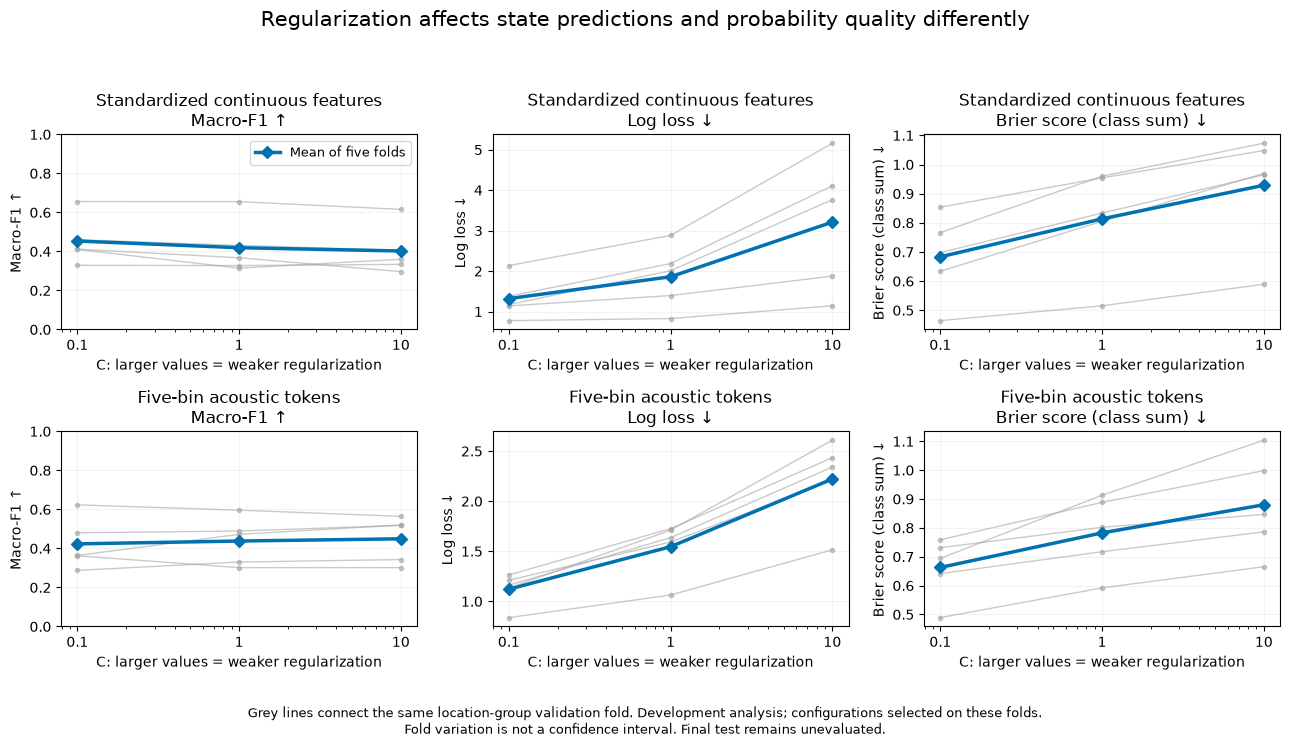

PAIRED CHANGE: C=10 MINUS C=0.1
metric                        brier_sum  log_loss  macro_f1
representation          fold                               
continuous_standardized 0        0.3351    2.5940   -0.0546
                        1        0.1248    0.3667   -0.0404
                        2        0.1944    3.0247   -0.0505
                        3        0.3064    2.7322   -0.1153
                        4        0.2668    0.7360    0.0048
five_bin_onehot         0        0.1447    1.1797    0.0379
                        1        0.1763    0.6773   -0.0590
                        2        0.2398    1.1709    0.0556
                        3        0.1153    0.9991    0.1561
                        4        0.4095    1.4756   -0.0608

Positive macro-F1 change is better.
Negative log-loss/Brier change is better.

Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\logistic_comparison_20261030T033349808226Z
No models fitted. Selected 

In [6]:
# Regularization: classification versus probability quality
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

logistic_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1"
    / "logistic_comparison_20261030T033349808226Z"
)

scores = pd.read_csv(logistic_dir / "fold_metrics.csv")

required = {
    "representation", "C", "fold",
    "macro_f1", "log_loss", "brier_sum"
}
missing = required - set(scores.columns)
assert not missing, f"Missing columns: {sorted(missing)}"

representations = {
    "continuous_standardized": "Standardized continuous features",
    "five_bin_onehot": "Five-bin acoustic tokens",
}
c_values = [0.1, 1.0, 10.0]
metrics = [
    ("macro_f1", "Macro-F1 ↑"),
    ("log_loss", "Log loss ↓"),
    ("brier_sum", "Brier score (class sum) ↓"),
]

assert not scores.duplicated(["representation", "C", "fold"]).any()
assert set(scores["fold"]) == set(range(5))

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
paired_rows = []

for row, (representation, title) in enumerate(representations.items()):
    subset = scores.loc[
        scores["representation"].eq(representation)
    ].copy()

    for col, (metric, label) in enumerate(metrics):
        ax = axes[row, col]
        wide = subset.pivot(
            index="fold", columns="C", values=metric
        ).reindex(index=range(5), columns=c_values)

        assert wide.shape == (5, 3)
        assert np.isfinite(wide.to_numpy()).all()

        for fold, values in wide.iterrows():
            ax.plot(
                c_values, values, color="0.65", alpha=0.6,
                marker="o", markersize=3, linewidth=1
            )

        ax.plot(
            c_values, wide.mean(), color="#0072B2",
            marker="D", linewidth=2.5, label="Mean of five folds"
        )
        ax.set_xscale("log")
        ax.set_xticks(c_values, labels=["0.1", "1", "10"])
        ax.set_xlabel("C: larger values = weaker regularization")
        ax.set_ylabel(label)
        ax.set_title(f"{title}\n{label}")
        ax.grid(alpha=0.15)

        if metric == "macro_f1":
            ax.set_ylim(0, 1)
        if row == 0 and col == 0:
            ax.legend(fontsize=9)

        for fold in wide.index:
            paired_rows.append({
                "representation": representation,
                "metric": metric,
                "fold": int(fold),
                "C_0.1": float(wide.loc[fold, 0.1]),
                "C_10": float(wide.loc[fold, 10.0]),
                "change_C10_minus_C0.1": float(
                    wide.loc[fold, 10.0] - wide.loc[fold, 0.1]
                ),
            })

fig.suptitle(
    "Regularization affects state predictions and probability quality differently",
    fontsize=15
)
fig.text(
    0.5, 0.015,
    "Grey lines connect the same location-group validation fold. "
    "Development analysis; configurations selected on these folds.\n"
    "Fold variation is not a confidence interval. Final test remains unevaluated.",
    ha="center", fontsize=9
)
fig.tight_layout(rect=[0, 0.08, 1, 0.94])

for extension in ("png", "svg"):
    fig.savefig(
        logistic_dir / f"regularization_tradeoff.{extension}",
        dpi=220, bbox_inches="tight"
    )
plt.show()

paired = pd.DataFrame(paired_rows)
paired.to_csv(
    logistic_dir / "regularization_paired_changes.csv", index=False
)

print("PAIRED CHANGE: C=10 MINUS C=0.1")
print(
    paired.pivot(
        index=["representation", "fold"],
        columns="metric",
        values="change_C10_minus_C0.1"
    ).round(4).to_string()
)
print("\nPositive macro-F1 change is better.")
print("Negative log-loss/Brier change is better.")
print("\nSaved:", logistic_dir)
print("No models fitted. Selected configurations unchanged.")
print("Final test remains unevaluated.")

In [7]:
# Register nested location-group learning subsets
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd

fractions = [0.25, 0.50, 0.75, 1.00]
sampling_seeds = [42, 137, 2026]

fm = fold_manifest.reset_index(drop=True).copy()
required = {
    "recording_id", "model_state", "location_group", "validation_fold"
}
assert required.issubset(fm.columns)
assert fm["recording_id"].is_unique
assert fm[list(required)].notna().all().all()
assert len(fm) == len(X) == len(y) == 184
assert np.array_equal(
    fm["model_state"].astype(str).to_numpy(),
    np.asarray(y).astype(str)
)
assert set(fm["validation_fold"]) == set(range(5))

# Every exact-coordinate group must belong to one state and one fold.
assert fm.groupby("location_group")["model_state"].nunique().eq(1).all()
assert fm.groupby("location_group")["validation_fold"].nunique().eq(1).all()

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
learning_dir = (
    PROJECT_ROOT / "data/processed/supervised/v1"
    / f"location_learning_curves_{stamp}"
)
learning_dir.mkdir(parents=True, exist_ok=False)

protocol = {
    "purpose": "Development performance as training location groups increase",
    "fractions": fractions,
    "sampling_seeds": sampling_seeds,
    "sampling": (
        "Within each outer training fold and state, permute groups once "
        "per seed; take nested prefixes using ceiling(fraction * groups)."
    ),
    "models": {
        "Multinomial NB": {
            "bins": 5, "alpha": 1.0, "fit_prior": True
        },
        "Gini depth 3": {
            "criterion": "gini", "max_depth": 3,
            "min_samples_leaf": 5, "ccp_alpha": 0.0,
            "random_state": 42
        }
    },
    "validation": "Existing development folds; unchanged at every fraction",
    "preprocessing": "Fit only on each selected training subset",
    "tuning": "None; configurations fixed from earlier development analyses",
    "full_fraction": (
        "Identical across sampling seeds; fit once per model and fold, "
        "not treated as three independent observations."
    ),
    "limitations": [
        "Exact coordinates are a grouping proxy, not verified independent sites.",
        "More groups also add recordings and may change species composition.",
        "Exploratory development analysis; model settings previously selected "
        "using these development folds."
    ],
    "final_test_evaluated": False
}

assignment_rows = []
support_rows = []

for fold in range(5):
    train = fm.loc[fm["validation_fold"].ne(fold)]
    valid = fm.loc[fm["validation_fold"].eq(fold)]
    validation_groups = set(valid["location_group"])

    groups = train[
        ["location_group", "model_state"]
    ].drop_duplicates().sort_values(["model_state", "location_group"])

    full_training_groups = set(groups["location_group"])

    for seed in sampling_seeds:
        rng = np.random.default_rng(seed + 1000 * fold)
        ordered_groups = {
            state: rng.permutation(
                block["location_group"].to_numpy()
            ).tolist()
            for state, block in groups.groupby("model_state", sort=True)
        }

        previous_groups = set()

        for fraction in fractions:
            selected_groups = set()
            for state, group_list in ordered_groups.items():
                count = max(1, int(np.ceil(fraction * len(group_list))))
                selected_groups.update(group_list[:count])

            assert previous_groups.issubset(selected_groups)
            assert selected_groups.isdisjoint(validation_groups)
            if fraction == 1.0:
                assert selected_groups == full_training_groups

            subset = train.loc[
                train["location_group"].isin(selected_groups)
            ]
            assert set(subset["model_state"]) == {"AZ", "CA", "TX"}

            for record in subset[
                ["recording_id", "model_state", "location_group"]
            ].to_dict("records"):
                assignment_rows.append({
                    "fold": fold, "seed": seed,
                    "fraction": fraction, **record
                })

            support = {
                "fold": fold, "seed": seed, "fraction": fraction,
                "training_groups": len(selected_groups),
                "training_recordings": len(subset),
                "validation_recordings": len(valid)
            }
            for state in ["AZ", "CA", "TX"]:
                state_subset = subset.loc[subset["model_state"].eq(state)]
                support[f"{state}_groups"] = (
                    state_subset["location_group"].nunique()
                )
                support[f"{state}_recordings"] = len(state_subset)

            support_rows.append(support)
            previous_groups = selected_groups

learning_assignments = pd.DataFrame(assignment_rows)
learning_support = pd.DataFrame(support_rows)

assert not learning_assignments.duplicated(
    ["fold", "seed", "fraction", "recording_id"]
).any()

learning_assignments.to_csv(
    learning_dir / "training_assignments.csv", index=False
)
learning_support.to_csv(
    learning_dir / "subset_support.csv", index=False
)
fm.to_csv(learning_dir / "development_fold_manifest.csv", index=False)
with open(learning_dir / "protocol.json", "w", encoding="utf-8") as handle:
    json.dump(protocol, handle, indent=2)

print("TRAINING SUPPORT ACROSS FOLDS AND SAMPLING SEEDS")
print(
    learning_support.groupby("fraction").agg(
        min_groups=("training_groups", "min"),
        max_groups=("training_groups", "max"),
        min_recordings=("training_recordings", "min"),
        max_recordings=("training_recordings", "max"),
        minimum_AZ=("AZ_recordings", "min"),
        minimum_CA=("CA_recordings", "min"),
        minimum_TX=("TX_recordings", "min")
    ).to_string()
)
print("\nNested subsets and group separation: PASS")
print("Saved:", learning_dir)
print("No models fitted. Final test remains unevaluated.")

TRAINING SUPPORT ACROSS FOLDS AND SAMPLING SEEDS
          min_groups  max_groups  min_recordings  max_recordings  minimum_AZ  minimum_CA  minimum_TX
fraction                                                                                            
0.25              27          29              29              54           7          12           9
0.50              54          56              65              93          18          24          19
0.75              81          83              97             123          26          36          30
1.00             108         109             131             154          36          50          40

Nested subsets and group separation: PASS
Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\supervised\v1\location_learning_curves_20261030T223013546553Z
No models fitted. Final test remains unevaluated.
